In [5]:
import math
import numpy as np
import matplotlib.pyplot as plt
import japanize_matplotlib

In [6]:
np.random.seed(0)

In [7]:
alpha = 11
lam = 13

epsilon = 0.05
L = 15

# リープフロッグでの遷移

In [8]:
# 式5.51
def h(theta):
	return lam * theta - (alpha-1) * math.log(theta)

# 式5.52
def dh(theta):
	return lam - (alpha - 1) / theta

# ハミルトニアン
def H(theta, p):
	return h(theta) + p**2 / 2

def leapfrog_step(theta, p, epsilon):
	# 運動量を半ステップ進める。式5.31
	p_half = p - epsilon / 2 * dh(theta)

	# 位置を1ステップ進める。式5.32
	theta_new = theta + epsilon * p_half

	# 運動量をさらに半ステップ進める。式5.33
	p_new = p_half - epsilon / 2 * dh(theta_new)

	return theta_new, p_new

theta0 = 0.1
p0 = 0.0

theta = theta0
p = p0

print(
	f"{'tau':>3} "
	f"{'p':>8} "
	f"{'theta':>8} "
	f"{'h(theta)':>10} "
	f"{'H(theta,p)':>12}"
)
for tau in range(1, L + 1):
	print(
		f"{tau:3d} "
		f"{p:8.2f} "
		f"{theta:8.2f} "
		f"{h(theta):10.2f} "
		f"{H(theta, p):12.2f}"
	)
	# リープフロッグ法で更新
	if tau < L:
		theta, p = leapfrog_step(theta, p, epsilon)


tau        p    theta   h(theta)   H(theta,p)
  1     0.00     0.10      24.33        24.33
  2     3.05     0.21      18.38        23.02
  3     4.21     0.40      14.31        23.18
  4     4.58     0.63      12.81        23.29
  5     4.61     0.86      12.69        23.34
  6     4.48     1.09      13.31        23.36
  7     4.25     1.31      14.33        23.38
  8     3.96     1.52      15.55        23.39
  9     3.62     1.71      16.84        23.39
 10     3.25     1.88      18.12        23.40
 11     2.86     2.03      19.32        23.40
 12     2.44     2.16      20.41        23.40
 13     2.02     2.28      21.36        23.40
 14     1.58     2.37      22.15        23.40
 15     1.14     2.43      22.75        23.40


# HMC

In [9]:
def hmc_step(theta_current):
	# 運動量を標準正規分布から発生
	p_current = np.random.normal(0.0, 1.0)

	theta = theta_current
	p = p_current
	H_current = H(theta, p)

	# リープフロッグで更新
	for _ in range(L):
		theta, p = leapfrog_step(theta, p, epsilon)

	theta_prop = theta
	p_prop = p

	# 提案状態でのハミルトニアン
	H_prop = H(theta_prop, p_prop)

	# メトロポリス受容確率
	accept_prob = min(1, np.exp(H_current - H_prop))

	u = np.random.uniform(0.0, 1.0)

	if u < accept_prob:
		return theta_prop, True
	else:
		return theta_current, False

# HMC の実行

In [10]:
# HMC の実行回数
T = 1000

theta = 2.5

theta_samples = [theta]
accepted = 0

for t in range(T):
	theta, accept = hmc_step(theta)
	theta_samples.append(theta)

	if accept:
		accepted += 1

print("受容数 =", accepted)
print("受容率 =", accepted / T)


受容数 = 997
受容率 = 0.997


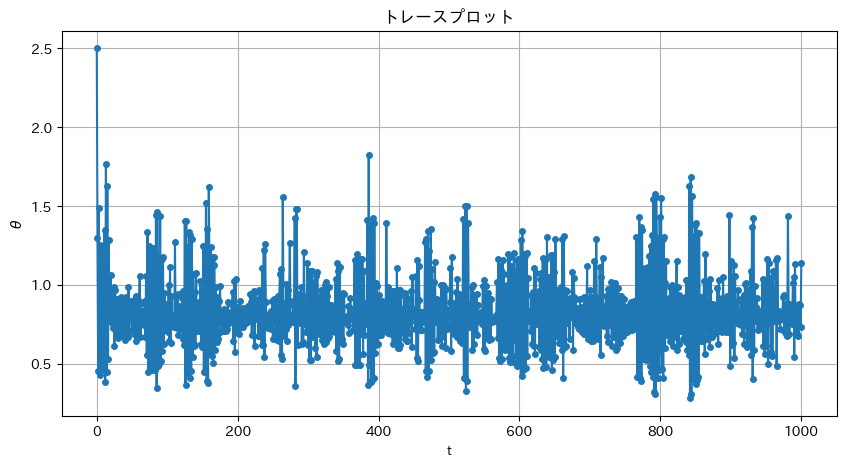

In [11]:
plt.figure(figsize=(10, 5))

plt.plot(
	range(T + 1),
	theta_samples,
	marker="o",
	markersize=4
)

plt.xlabel("t")
plt.ylabel(r"$\theta$")
plt.title("トレースプロット")

plt.grid()

plt.show()

In [12]:
burn_in = 10
samples = np.array(theta_samples)
samples_after_burnin = samples[burn_in:]
mean_theta = np.mean(samples_after_burnin)

print("バーンイン =", burn_in)
print("バーンイン後のサンプル数 =", len(samples_after_burnin))
print("theta の平均 =", mean_theta)

バーンイン = 10
バーンイン後のサンプル数 = 991
theta の平均 = 0.8406290053960358
